# 2주차 실습. GIN 을 한 층씩 뜯어보기

1주차에는 분자를 **고정된 벡터**(descriptor, Morgan)로 바꾼 뒤 모델에 넣었다.
GIN 은 분자 그래프를 그대로 받아 **벡터를 만드는 방법까지 학습**한다.

| 단계 | 셀 | 연구실 코드에서 |
|---|---|---|
| 1 | 분자 -> 그래프 텐서 (`x`, `edge_index`, `edge_attr`) | `feature.py : mol_to_features` |
| 2 | GIN 한 층을 손으로 계산하고 PyG 결과와 맞춰보기 | `torch_geometric.nn.models.GIN` |
| 3 | sum / mean / max 가 구분하는 것과 못 하는 것 | GIN 논문의 핵심 |
| 4 | 여러 분자를 한 배치로 묶기, 분자 벡터 만들기 (readout) | `global_mean_pool` |
| 5 | 학습 -> 1주차 결과표에 한 줄 추가 | `architecture.py : BGNN_unary.fit` |

이 폴더의 `feature.py`, `datamanager.py`, `models.py`, `train.py` 를 import 해서 쓴다.

In [1]:
import numpy as np, torch, matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Draw
from feature import smiles_to_graph, NODE_FEATURE_NAMES, EDGE_FEATURE_NAMES
torch.manual_seed(0)
plt.rcParams.update({'font.size': 12})

## 1. 분자 = 그래프
피페리딘(C1CCNCC1)은 원자 6개, 결합 6개다. 수소는 노드로 넣지 않고 원자 특징(`numH`)으로 넣는다.

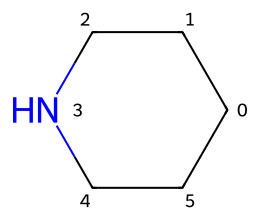

In [2]:
smi = 'C1CCNCC1'
mol = Chem.MolFromSmiles(smi)
for a in mol.GetAtoms():
    a.SetProp('atomNote', str(a.GetIdx()))
Draw.MolToImage(mol, size=(260, 220))

In [3]:
x, edge_index, edge_attr = smiles_to_graph(smi)
print('x          :', tuple(x.shape), '  원자 6개 x 원자 특징', x.shape[1])
print('edge_index :', tuple(edge_index.shape), ' 결합 6개 x 양방향 = 엣지 12개')
print('edge_attr  :', tuple(edge_attr.shape))
print(edge_index)

x          : (6, 147)   원자 6개 x 원자 특징 147
edge_index : (2, 12)  결합 6개 x 양방향 = 엣지 12개
edge_attr  : (12, 16)
tensor([[0, 1, 1, 2, 2, 3, 3, 4, 4, 5, 5, 0],
        [1, 0, 2, 1, 3, 2, 4, 3, 5, 4, 0, 5]])


**원자 하나의 특징 벡터 읽기.** 147칸 중 대부분은 0이다. 3번 원자(N)에서 1인 칸만 출력한다.

In [4]:
def on(vec, names):
    return [names[i] for i in torch.nonzero(vec).ravel().tolist()]
print('atom 3 (N):', on(x[3], NODE_FEATURE_NAMES))
print('atom 0 (C):', on(x[0], NODE_FEATURE_NAMES))
print('bond 0-1  :', on(edge_attr[0], EDGE_FEATURE_NAMES))

atom 3 (N): ['element=N', 'charge=0', 'hybrid=SP3', 'numH=1', 'valence=3', 'degree=3', 'in_ring', 'FG:Nitrogen', 'FG:sp3 nitrogen', 'FG:Hydrogen-bond acceptor#1', 'FG:Hydrogen-bond donor#0', 'FG:Hydrogen-bond donor#1']
atom 0 (C): ['element=C', 'charge=0', 'hybrid=SP3', 'numH=2', 'valence=4', 'degree=4', 'in_ring', 'FG:Alkyl Carbon']
bond 0-1  : ['single', 'begin=C', 'end=C']


> 질문. 1주차의 Morgan fingerprint 와 무엇이 같고 무엇이 다른가?
> 원자 특징은 **원자 하나**만 본다. 주변 정보는 아직 없다. 주변을 섞는 것이 다음 단계의 message passing 이다.

## 2. GIN 한 층 손으로 계산하기
GIN 의 갱신식 (Xu et al., ICLR 2019):

$$h_v^{(k)} = \mathrm{MLP}^{(k)}\Big((1+\epsilon)\, h_v^{(k-1)} + \sum_{u \in N(v)} h_u^{(k-1)}\Big)$$

1. **message**: 이웃 $u$ 가 자기 벡터 $h_u$ 를 보낸다
2. **aggregate**: 받은 것을 **더한다** (평균이나 최댓값이 아니라 합)
3. **update**: 자기 자신$(1+\epsilon)h_v$ 을 더하고 MLP 에 통과시킨다

`edge_index` 의 첫 줄이 보내는 쪽(source), 둘째 줄이 받는 쪽(target)이다.

In [5]:
from torch_geometric.nn import GINConv

mlp = torch.nn.Sequential(torch.nn.Linear(x.shape[1], 8), torch.nn.ReLU(), torch.nn.Linear(8, 8))
conv = GINConv(mlp, eps=0.0)

# 손 계산
src, dst = edge_index
agg = torch.zeros_like(x).index_add_(0, dst, x[src])      # 받는 원자마다 이웃 벡터 합
h_manual = mlp((1 + 0.0) * x + agg)

# PyG
h_pyg = conv(x, edge_index)
print('손 계산 == PyG :', torch.allclose(h_manual, h_pyg, atol=1e-6))
print('출력 크기       :', tuple(h_pyg.shape), ' 원자 6개 x 8차원')

손 계산 == PyG : True
출력 크기       : (6, 8)  원자 6개 x 8차원


**층을 쌓으면 보는 범위가 넓어진다.** k 층을 지나면 원자 하나의 벡터에 k 결합 거리 안의 원자 정보가 들어간다.
연구실 모델은 5층이다. 아래 셀은 N(3번) 원자에 몇 층째에 어떤 원자 정보가 도착하는지 센다.

In [6]:
A = torch.zeros(6, 6); A[edge_index[1], edge_index[0]] = 1
reach = torch.eye(6)
for k in range(1, 4):
    reach = ((torch.eye(6) + A) @ reach > 0).float()
    print(f'{k}층 뒤 N(3) 이 본 원자:', torch.nonzero(reach[3]).ravel().tolist())

1층 뒤 N(3) 이 본 원자: [2, 3, 4]
2층 뒤 N(3) 이 본 원자: [1, 2, 3, 4, 5]
3층 뒤 N(3) 이 본 원자: [0, 1, 2, 3, 4, 5]


## 3. 왜 sum 인가
이웃이 {C, C} 인 원자와 {C, C, C, C} 인 원자를 생각하자. 원자 특징이 같다면
- **mean**: 둘 다 C 의 평균 = 같다 -> 구분 못 함
- **max**: 둘 다 C = 같다 -> 구분 못 함
- **sum**: 2C 와 4C -> 구분함

GIN 이 sum 을 쓰는 이유다. 구분 능력이 그래프 동형 판별(WL test)과 같아지는 조건이 "합 + MLP" 다.

In [7]:
c = torch.tensor([1., 0.])                     # 탄소 하나의 특징이라고 하자
two, four = torch.stack([c, c]), torch.stack([c, c, c, c])
for name, f in [('mean', lambda t: t.mean(0)), ('max', lambda t: t.max(0).values), ('sum', lambda t: t.sum(0))]:
    print(f'{name:4s}: 이웃 2개 {f(two).tolist()}  이웃 4개 {f(four).tolist()}  ->',
          '같음' if torch.equal(f(two), f(four)) else '다름')

mean: 이웃 2개 [1.0, 0.0]  이웃 4개 [1.0, 0.0]  -> 같음
max : 이웃 2개 [1.0, 0.0]  이웃 4개 [1.0, 0.0]  -> 같음
sum : 이웃 2개 [2.0, 0.0]  이웃 4개 [4.0, 0.0]  -> 다름


> 연구실 모델에서 확인할 것: 원자 사이(aggregate)는 GIN 의 sum 이지만,
> **원자 벡터를 분자 벡터로 바꾸는 readout 은 `global_mean_pool` (평균)** 이다.
> 그래서 분자 크기 정보가 평균에서 일부 사라진다. 5단계에서 `pooling='sum'` 과 비교해 본다.
>
> 또 하나. PyG 의 `GIN` 은 **결합 특징 `edge_attr` 를 쓰지 않는다**. 아래 셀로 확인한다.

In [8]:
from torch_geometric.nn.models import GIN
print('GIN.supports_edge_attr =', GIN.supports_edge_attr)

GIN.supports_edge_attr = False


## 4. 배치와 readout
분자마다 원자 수가 다르다. PyG 는 여러 분자를 **하나의 큰 그래프**로 이어 붙이고,
`batch` 벡터로 "이 원자는 몇 번째 분자 것인가"를 적어 둔다.

In [9]:
from torch_geometric.data import Data, Batch
from torch_geometric.nn import global_mean_pool, global_add_pool
graphs = []
for s in ['C1CCNCC1', 'NCCO', 'c1ccccc1']:
    xx, ei, ea = smiles_to_graph(s)
    graphs.append(Data(x=xx, edge_index=ei, edge_attr=ea))
b = Batch.from_data_list(graphs)
print('합친 x     :', tuple(b.x.shape))
print('batch 벡터 :', b.batch.tolist())
print('mean pool  :', tuple(global_mean_pool(b.x, b.batch).shape), ' 분자 3개 x 147')
print('sum pool의 원자 수 칸 합(=분자 크기 정보) :', global_add_pool(b.x, b.batch)[:, :11].sum(1).tolist())

합친 x     : (16, 147)
batch 벡터 : [0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2]
mean pool  : (3, 147)  분자 3개 x 147
sum pool의 원자 수 칸 합(=분자 크기 정보) : [6.0, 4.0, 6.0]


## 5. 학습해서 1주차 표에 한 줄 추가
`train.run()` 이 연구실 실제 학습 설정(GIN 5층, hidden 128, fingerprint 64, dropout 0.3, batch 64, AdamW 1e-3)으로 학습한다.
수업 시간에는 `max_n=2000`, `epochs=80` 으로 줄인다. 집에서는 `train.py` 를 터미널에서 돌린다.

```bash
python train.py --prop logP                  # 5,000개, 약 2분 (CPU)
python train.py --prop logP --split scaffold
python train.py --prop logP --conv GINE      # 결합 특징 사용
python train.py --prop logP --pooling sum
python train.py --prop logP --bayes          # 불확실성
```

In [10]:
from train import run
res = run(prop='mp', max_n=2000, epochs=80, outdir='results_nb', verbose=False)   # [수정] 팀 물성 mp (수업용 축소 설정 그대로)
res

[load_data] mp: 2,000 rows, unit = K


[gen_dataset] 2,000 graphs, node features = 147, edge features = 16
[split_dataset:random] train 1,600 / validate 200 / test 200


[test] mp_GNN-GIN_mean_random: MAE 38.691 | RMSE 53.178 | R2 0.648 | baseline MAE 70.741 | 80 epochs, 47 s


{'prop': 'mp',
 'model': 'GNN-GIN',
 'pooling': 'mean',
 'split': 'random',
 'n': 2000,
 'epochs': 80,
 'sec': 46.5,
 'MAE': 38.69093704223633,
 'RMSE': 53.17792510986328,
 'R2': 0.6476635336875916,
 'baseline_MAE': 70.74052429199219,
 'mean_sd': nan,
 'coverage_2sd': nan}

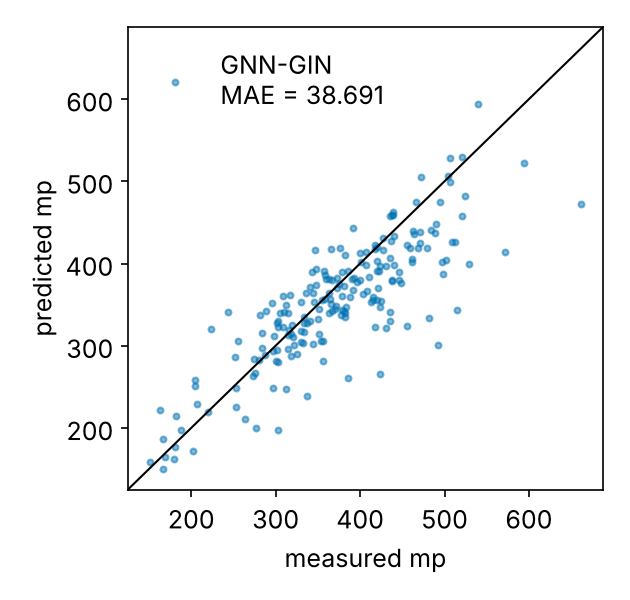

In [11]:
from IPython.display import Image
Image('results_nb/mp_GNN-GIN_mean_random_parity.png')

## 6. 팀 과제
1. 우리 팀 물성으로 `train.py` 를 돌려 **GNN-GIN 줄**을 1주차 결과표에 추가한다 (random, scaffold 둘 다)
2. 아래 셋 중 둘을 바꿔보고 MAE 변화를 표로 낸다
   - `--pooling sum` (readout 을 합으로)
   - `--conv GINE` (결합 특징 사용) vs `--conv GCN`
   - 층 수 (`num_layers` 1, 3, 5, 7) -> 3절의 "보는 범위"와 연결해 해석
3. `--bayes` 로 돌린 뒤 `results/*_test_pred.csv` 의 `sd`(불확실성)가 큰 분자 5개를 그려보고,
   학습 세트에 비슷한 분자가 있었는지 확인한다
4. 토론: 1주차의 Random Forest + descriptor 보다 GIN 이 나은가? 데이터 수가 몇 개일 때 역전되는가?

**규칙**은 1주차와 같다. test 성능을 보고 설정을 고르지 않는다. 고를 때는 validate MAE 를 본다.